## CS 329E - Data Science
#### Fall 2026 - Group 8
Name: Eduardo Borges Issa

EID: eb34276

Name: Cheve Garcia

EID: gcg837

Dataset: UCI Adult Dataset (Census Income dataset), extracted from the 1994 US Census Bureau database. It contains demographic, financial, and employment records for approximately 32,561 instances. (https://archive.ics.uci.edu/dataset/2/adult)

#### Problem Statement & Research Question
The research question will investigate what demographic and employment features best predict annual incomes exceeding $50,000, and how effectively class imbalance resampling can mitigate minority class misclassification. To satisfy the requirement for an uncovered technique, the project will be done with SMOTE (Synthetic Minority Over-sampling Technique), which will generate synthetic minority instances by interpolating feature-space nearest neighbors via Euclidean distance to avoid the overfitting risks of naive random duplication. 


In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

%matplotlib inline

In [44]:
# load the training dataset from the 'adult' subfolder
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income",
]

# load only adult.data
df = pd.read_csv("adult/adult.data", header=None, names=columns, skipinitialspace=True, na_values="?")
print(f"Raw dataset shape: {df.shape}")

n_dup = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dup}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df.shape}")
df.head()

Raw dataset shape: (32561, 15)
Exact duplicate rows: 24
Shape after removing duplicates: (32537, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [45]:
# data cleaning & missing values
# whitespace -> nan
df = df.replace(r"^\s*\?\s*$", np.nan, regex=True)

str_cols = df.select_dtypes(exclude="number").columns
df[str_cols] = df[str_cols].apply(lambda x: x.str.strip())

print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# drop rows with missing values
df_clean = df.dropna().copy()
print(f"\nOriginal shape: {df.shape}")
print(f"Shape after dropping missing rows: {df_clean.shape}")

Missing values per column:
workclass         1836
occupation        1843
native_country     582
dtype: int64

Original shape: (32537, 15)
Shape after dropping missing rows: (30139, 15)


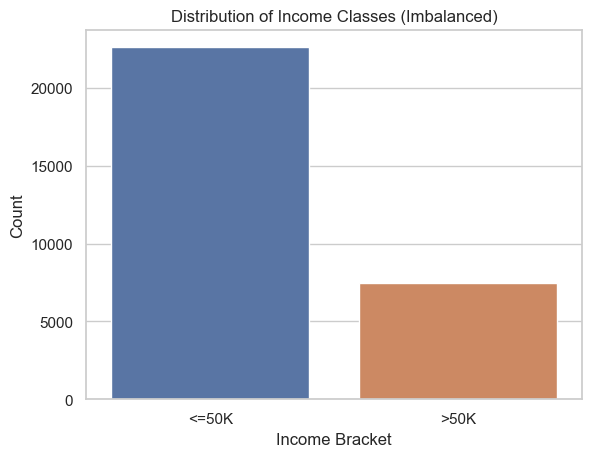

In [47]:
# distribution visualization
sns.countplot(x="income", hue="income", data=df_clean)
plt.title("Distribution of Income Classes (Imbalanced)")
plt.xlabel("Income Bracket")
plt.ylabel("Count")
plt.show()

The above graphic shows the need for SMOTE: with an imbalanced dataset like this (where the majority of the datapoints are from those who make less than $50k a year), SMOTE can help the machine learning algorithm by generating new data to fill the gaps. These 'fake' data points are created before the model is trained, so that the model can properly learn correctly despite the imbalanced data.